# Реальные данные: продажи апельсинового сока в сети Dominick's

Проверяем многоиндексную модель с латентными факторами
$$
Y_{it}=c_i+X_{it}^\top P^\top\ell_i+\gamma_i^\top f_t+\varepsilon_{it}
$$
на недельных продажах охлаждённого апельсинового сока в 83 магазинах сети Dominick's Finer Foods (Чикаго). Данные — выборка из базы Dominick's, распространяемая в R-пакете `bayesm` (датасет `orangeJuice`, источник: Montgomery, 1997).

- **индивид** — магазин ($n=83$);
- **время** — неделя ($T=121$), около 4% пар «магазин × неделя» отсутствуют;
- **отклик** — логарифм числа проданных упаковок одной марки;
- **признаки** — логарифмы цен всех 11 марок в этом магазине в эту неделю и индикатор купонной акции на эту марку ($d=12$). Тогда коэффициент при логарифме своей цены — собственная эластичность, при ценах других марок — перекрёстные эластичности.

Каждую из 11 марок разбираем как отдельную панель.

**Как получить данные.** В R: `library(bayesm); data(orangeJuice); write.csv(orangeJuice$yx, "orangejuice_yx.csv", row.names = FALSE)`, затем положить файл рядом с ноутбуком.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
BRANDS = ['Tropicana Premium 64', 'Tropicana Premium 96', "Florida's Natural 64", 'Tropicana 64', 'Minute Maid 64',
          'Minute Maid 96', 'Citrus Hill 64', 'Tree Fresh 64', 'Florida Gold 64', 'Dominicks 64', 'Dominicks 128']
FEATS = [f'ln p{k}' for k in range(1, 12)] + ['deal', 'feat']
RAW = pd.read_csv('orangejuice_yx.csv')
print(RAW.shape)
RAW.head(3)

(106139, 19)


,store,brand,week,logmove,constant,price1,price2,price3,price4,price5,price6,price7,price8,price9,price10,price11,deal,feat,profit
0,2,1,40,9.018695,1,0.060469,0.060497,0.042031,0.029531,0.049531,0.053021,0.038906,0.041406,0.028906,0.024844,0.038984,1,0.0,37.992326
1,2,1,46,8.723231,1,0.060469,0.060312,0.045156,0.046719,0.049531,0.047813,0.045781,0.027969,0.042969,0.042031,0.038984,0,0.0,30.126667
2,2,1,47,8.253228,1,0.060469,0.060312,0.045156,0.046719,0.037344,0.053021,0.045781,0.041406,0.048125,0.032656,0.038984,0,0.0,30.000000


## 1. Подготовка панели

Для каждой марки строим массивы $Y$ ($n\times T$), $X$ ($n\times T\times d$) и маску наблюдённых клеток.

In [2]:
def load_panel(brand):
    g = RAW[RAW.brand == brand]
    stores = np.sort(g.store.unique()); weeks = np.sort(RAW.week.unique())
    si = {s: k for k, s in enumerate(stores)}; wi = {w: k for k, w in enumerate(weeks)}
    n, T = len(stores), len(weeks)
    Y = np.zeros((n, T)); X = np.zeros((n, T, 13)); mask = np.zeros((n, T), bool)
    i = g.store.map(si).values; t = g.week.map(wi).values
    Y[i, t] = g.logmove.values
    X[i, t, :11] = np.log(g[[f'price{k}' for k in range(1, 12)]].values)
    X[i, t, 11] = g.deal.values; X[i, t, 12] = g.feat.values
    mask[i, t] = True
    return Y, X, mask

Y, X, mask = load_panel(1)
print(f'n = {Y.shape[0]}, T = {Y.shape[1]}, наблюдено {mask.mean():.1%} клеток')

n = 83, T = 121, наблюдено 96.1% клеток


## 2. Признаки почти одинаковы во всех магазинах

Сеть меняет цены и рекламу во всех магазинах одновременно. Посчитаем, какая доля изменчивости каждого признака (после вычитания среднего по магазину) объясняется общим для всех магазинов эффектом недели.

In [3]:
rows = []
for k, name in enumerate(FEATS):
    V = np.where(mask, X[:, :, k], np.nan); V = V - np.nanmean(V, 1, keepdims=True)
    R = V - np.nanmean(V, 0)[None, :]
    rows.append([name, 1 - np.nanvar(R) / np.nanvar(V)])
common = pd.DataFrame(rows, columns=['признак', 'доля общей изменчивости']).set_index('признак')
common.T.round(2)

признак,ln p1,ln p2,ln p3,ln p4,ln p5,ln p6,ln p7,ln p8,ln p9,ln p10,ln p11,deal,feat
доля общей изменчивости,0.94,0.88,0.89,0.89,0.9,0.92,0.89,0.89,0.86,0.9,0.86,0.88,1.0


Почти вся изменчивость цен (около 90%) общая для сети, а реклама `feat` меняется во всех магазинах одновременно (100%). Отсюда два следствия:

1. **`feat` исключаем.** Признак, одинаковый для всех индивидов, неотличим от латентного фактора (нарушено условие идентифицируемости из раздела 3), поэтому дальше $d=12$.
2. **Старт по главным компонентам всей панели здесь не годится.** Факторы признаков (общие движения цен) он принимает за латентные факторы и «съедает» ценовую изменчивость. Поэтому факторы стартуют по остаткам регрессии без факторов. Из этого старта алгоритм тоже сходится, см. синтетику.

С факторами эластичности определяются по различиям цен между магазинами (у Dominick's есть ценовые зоны), а не по общим для сети изменениям цен.

## 3. Алгоритм для панели с пропусками

Те же шаги, что в основном ноутбуке, но по наблюдённым клеткам:
- **шаг по наклонам:** проекция для каждого магазина делается по его наблюдённым неделям: $M_i=I-$ проектор на $\mathrm{span}(\mathbf 1,F_{O_i})$. Лемма о проекции при этом остаётся верной;
- **шаг по факторам:** $\min\sum_{(i,t)\ \text{наблюдены}}(W_{it}-c_i-\gamma_i^\top f_t)^2$ решаем чередованием $(c_i,\gamma_i)\leftrightarrow f_t$. Каждый подшаг — обычная регрессия, поэтому критерий по-прежнему не возрастает.

In [4]:
def unit_stats(X, Y, mask, F):
    n, T, d = X.shape
    G = np.zeros((n, d, d)); Z = np.zeros((n, d))
    for i in range(n):
        o = mask[i]
        H = np.ones((o.sum(), 1)) if F is None or F.shape[1] == 0 else np.column_stack([np.ones(o.sum()), F[o]])
        Q = np.linalg.qr(H)[0]
        MX = X[i, o] - Q @ (Q.T @ X[i, o])
        G[i] = MX.T @ MX; Z[i] = MX.T @ Y[i, o]
    return G, Z


def ols_slopes(G, Z, ridge=1e-8):
    return np.linalg.solve(G + ridge * np.eye(G.shape[1]), Z[..., None])[..., 0]


def principal_axes(Bmat, m):
    return np.linalg.svd(Bmat, full_matrices=False)[2][:m]


def lowrank_slopes(G, Z, P0, iters=5):
    n, d = Z.shape; m = P0.shape[0]
    if m >= d:                                       # полный ранг = МНК по каждому магазину
        Bmat = ols_slopes(G, Z); return np.eye(d), Bmat, Bmat
    Bm = P0.copy()
    for _ in range(iters):
        BG = np.einsum('ka,iab->ikb', Bm, G)
        Lm = np.linalg.solve(np.einsum('ikb,lb->ikl', BG, Bm) + 1e-10 * np.eye(m),
                             np.einsum('ka,ia->ik', Bm, Z)[..., None])[..., 0]
        A = np.einsum('ik,il,iab->kalb', Lm, Lm, G).reshape(m * d, m * d)
        rhs = np.einsum('ik,ia->ka', Lm, Z).reshape(m * d)
        Bm = np.linalg.solve(A + 1e-10 * np.eye(m * d), rhs).reshape(m, d)
    Bmat = Lm @ Bm; P = principal_axes(Bmat, m)
    return P, Bmat @ P.T, Bmat


def residuals(Y, X, Bmat):
    return Y - np.einsum('itd,id->it', X, Bmat)


def factor_step(W, mask, r, F0=None, inner=5):
    n, T = W.shape
    if r == 0:
        return np.zeros((T, 0)), np.array([W[i, mask[i]].mean() for i in range(n)]), np.zeros((n, 0))
    if F0 is None:
        c = np.array([W[i, mask[i]].mean() for i in range(n)])
        F = np.sqrt(T) * np.linalg.svd(np.where(mask, W - c[:, None], 0.0), full_matrices=False)[2][:r].T
    else:
        F = F0.copy()
    for _ in range(inner):
        C = np.array([np.linalg.lstsq(np.column_stack([np.ones(mask[i].sum()), F[mask[i]]]), W[i, mask[i]], rcond=None)[0] for i in range(n)])
        c, Gm = C[:, 0], C[:, 1:]
        for t in range(T):
            o = mask[:, t]; F[t] = np.linalg.lstsq(Gm[o], W[o, t] - c[o], rcond=None)[0]
    F = F - F.mean(0); F = np.sqrt(T) * np.linalg.svd(F, full_matrices=False)[0]
    C = np.array([np.linalg.lstsq(np.column_stack([np.ones(mask[i].sum()), F[mask[i]]]), W[i, mask[i]], rcond=None)[0] for i in range(n)])
    return F, C[:, 0], C[:, 1:]


def fit(Y, X, mask, m, r, max_iter=200, tol=1e-7):
    n, T, d = X.shape
    if r == 0:
        F = np.zeros((T, 0))
    else:                                            # старт: факторы по остаткам МНК без факторов
        G0, Z0 = unit_stats(X, Y, mask, None)
        F, _, _ = factor_step(residuals(Y, X, ols_slopes(G0, Z0)), mask, r)
    P = principal_axes(ols_slopes(*unit_stats(X, Y, mask, F)), min(m, d))
    hist = []
    for it in range(max_iter):
        G, Z = unit_stats(X, Y, mask, F)
        P, Lm, Bmat = lowrank_slopes(G, Z, P)
        F, c, Gm = factor_step(residuals(Y, X, Bmat), mask, r, F0=F if r > 0 else None)
        R = residuals(Y, X, Bmat) - c[:, None] - (Gm @ F.T if r else 0.0)
        hist.append(float(np.sum(R[mask] ** 2)))
        if r == 0 or (it > 0 and hist[-2] - hist[-1] < tol * hist[-1]):
            break
    return dict(P=P, B=Bmat, F=F, c=c, G=Gm, hist=np.array(hist))


def fit_twoway(Y, X, mask, max_iter=200, tol=1e-9):
    # свои наклоны у каждого магазина + общий эффект недели (фактор с нагрузками 1)
    n, T, d = X.shape; delta = np.zeros(T); prev = np.inf
    for _ in range(max_iter):
        Bmat = ols_slopes(*unit_stats(X, Y - delta[None, :], mask, None))
        W = residuals(Y, X, Bmat) - delta[None, :]
        c = np.array([W[i, mask[i]].mean() for i in range(n)])
        R = residuals(Y, X, Bmat) - c[:, None]
        delta = np.array([R[mask[:, t], t].mean() for t in range(T)]); delta -= delta.mean()
        s = float(np.sum((R - delta[None, :])[mask] ** 2))
        if prev - s < tol * s:
            break
        prev = s
    return dict(B=Bmat, c=c, delta=delta)

## 4. Подробный разбор одной марки: Tropicana Premium 64 oz

Сначала смотрим, видны ли факторы и малый ранг: сингулярные числа матрицы остатков после регрессии по каждому магазину (без факторов) и матрицы наклонов, оценённых МНК с одним фактором.

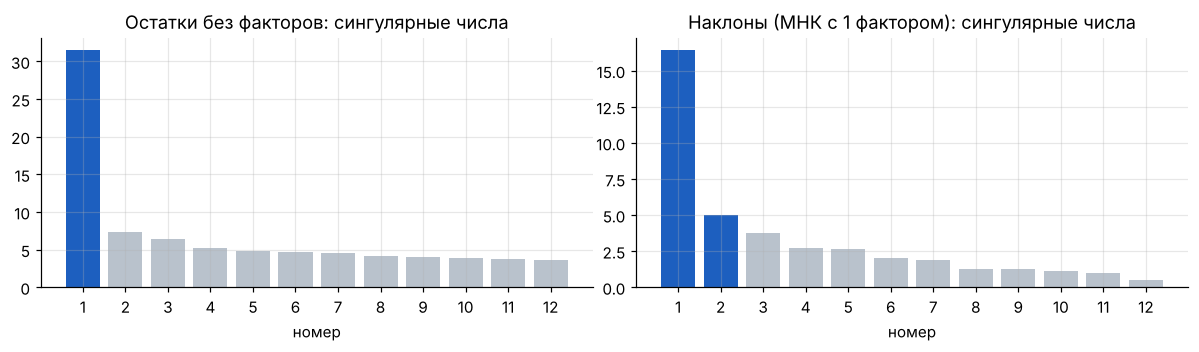

остатки: [31.5  7.4  6.4  5.2  4.8  4.7]
наклоны: [16.44  4.98  3.74  2.71  2.64  1.99]


In [5]:
Y, X, mask = load_panel(1); X = X[:, :, :12]; n, T, d = X.shape
G0, Z0 = unit_stats(X, Y, mask, None); B_ols = ols_slopes(G0, Z0)
W = residuals(Y, X, B_ols); c0 = np.array([W[i, mask[i]].mean() for i in range(n)])
s_res = np.linalg.svd(np.where(mask, W - c0[:, None], 0.0), compute_uv=False)
R1 = fit(Y, X, mask, m=d, r=1)
s_B = np.linalg.svd(R1['B'], compute_uv=False)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
k = np.arange(1, 13)
axs[0].bar(k, s_res[:12], color=['#1d5fbf'] + ['#b9c2cc'] * 11); axs[0].set_xticks(k)
axs[0].set_title('Остатки без факторов: сингулярные числа'); axs[0].set_xlabel('номер')
axs[1].bar(k, s_B[:12], color=['#1d5fbf'] * 2 + ['#b9c2cc'] * 10); axs[1].set_xticks(k)
axs[1].set_title('Наклоны (МНК с 1 фактором): сингулярные числа'); axs[1].set_xlabel('номер')
plt.tight_layout(); plt.show()
print('остатки:', np.round(s_res[:6], 1)); print('наклоны:', np.round(s_B[:6], 2))

В остатках один фактор явно доминирует: это общий для сети недельный шок. У наклонов первое сингулярное число намного больше остальных, второе тоже заметно выделяется. Дальше берём $m=2$, $r=1$; в разделе 5 эти числа выбираются автоматически по валидации, и для этой марки получаются те же.

In [6]:
R_ours = fit(Y, X, mask, m=2, r=1)
R_nof = fit(Y, X, mask, m=2, r=0)
R_olsf = fit(Y, X, mask, m=d, r=1)
print('итераций нашего метода:', len(R_ours['hist']),
      '| S не возрастает:', bool(np.all(np.diff(R_ours['hist']) <= 1e-9 * R_ours['hist'][0])))

def summary(B, name):
    e = B[:, 0]
    return [name, np.median(e), np.percentile(e, 25), np.percentile(e, 75), np.mean(e < 0), np.std(e)]

el = pd.DataFrame([summary(B_ols, 'МНК без факторов'), summary(R_nof['B'], 'многоиндексный без факторов'),
                   summary(R_olsf['B'], 'МНК + 1 фактор'), summary(R_ours['B'], 'наш метод (m=2, r=1)')],
                  columns=['способ', 'медиана', '25%', '75%', 'доля < 0', 'разброс по магазинам']).set_index('способ')
el.round(2)

итераций нашего метода: 137 | S не возрастает: True


,медиана,25%,75%,доля < 0,разброс по магазинам
способ,,,,,
МНК без факторов,-3.12,-3.48,-2.78,1.0,0.51
многоиндексный без факторов,-3.13,-3.40,-2.83,1.0,0.50
МНК + 1 фактор,-1.67,-1.96,-1.46,1.0,0.44
"наш метод (m=2, r=1)",-1.77,-2.05,-1.62,1.0,0.39


Собственная эластичность по цене у всех магазинов отрицательная. С факторами она по модулю меньше (около −1,7 против −3,1). Без факторов в неё попадает эффект общих для сети недельных шоков, которые совпадают со снижениями цен: сеть снижает цену и одновременно проводит рекламу и выкладку. Разброс эластичностей между магазинами у нашего метода меньше, чем у МНК с фактором, потому что малый ранг убирает шум.

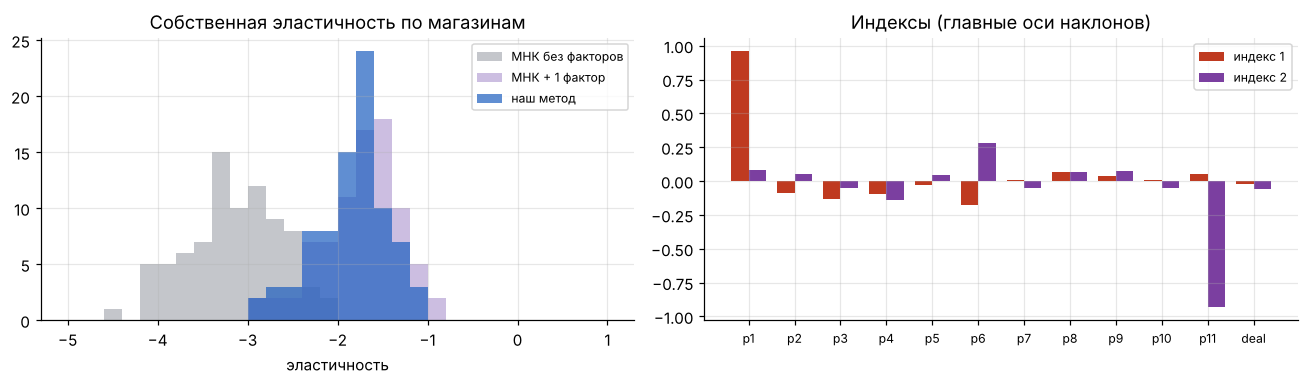

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(-5, 1, 31)
axs[0].hist(B_ols[:, 0], bins=bins, alpha=0.5, color='#8a8f98', label='МНК без факторов')
axs[0].hist(R_olsf['B'][:, 0], bins=bins, alpha=0.5, color='#9b7fc4', label='МНК + 1 фактор')
axs[0].hist(R_ours['B'][:, 0], bins=bins, alpha=0.7, color='#1d5fbf', label='наш метод')
axs[0].set_title('Собственная эластичность по магазинам'); axs[0].set_xlabel('эластичность'); axs[0].legend(fontsize=8)
lab = [f'p{k}' for k in range(1, 12)] + ['deal']
for j, c in enumerate(['#bf3a20', '#7b3fa0']):
    axs[1].bar(np.arange(12) + (j - 0.5) * 0.38, R_ours['P'][j], width=0.38, color=c, label=f'индекс {j + 1}')
axs[1].set_xticks(np.arange(12)); axs[1].set_xticklabels(lab, fontsize=8)
axs[1].set_title('Индексы (главные оси наклонов)'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


Индексы хорошо интерпретируются. Первый почти целиком нагружен на собственную цену марки (вес около 0.97): это реакция на свою цену. Второй в основном нагружен на цены больших упаковок, Dominicks 128 oz и Minute Maid 96 oz. Магазины различаются тем, насколько продажи марки зависят от цен больших упаковок, то есть от перехода покупателей на крупную тару. Знак индекса произволен, направление эффекта задают нагрузки $\ell_i$.


Корреляция остатков между магазинами. Если общий шок не учтён, остатки разных магазинов сильно коррелированы, и это нарушает предположения обычной регрессии. После учёта фактора корреляция должна заметно упасть.

In [8]:
def mean_abs_corr(R, mask):
    Rm = np.where(mask, R, np.nan); Rm = Rm - np.nanmean(Rm, 1, keepdims=True)
    C = pd.DataFrame(Rm.T).corr(min_periods=30).values
    return np.nanmean(np.abs(C[np.triu_indices_from(C, 1)]))

res_nof = residuals(Y, X, B_ols)
res_f = residuals(Y, X, R_ours['B']) - R_ours['c'][:, None] - R_ours['G'] @ R_ours['F'].T
print(f'средняя |корреляция| остатков между магазинами: без факторов {mean_abs_corr(res_nof, mask):.3f}, '
      f'после учёта фактора {mean_abs_corr(res_f, mask):.3f}')

средняя |корреляция| остатков между магазинами: без факторов 0.667, после учёта фактора 0.108


## 5. Проверка прогнозом на всех 11 марках

Истинных наклонов на реальных данных нет, поэтому сравниваем методы по прогнозу.

- **Обучение:** первые 97 недель, все магазины.
- **Тест:** последние 24 недели. Магазины случайно делятся пополам: продажи одной половины считаются известными, продажи другой нужно предсказать. Так устроены задачи «что было бы в магазине, где данных нет» и оценка эффекта мер, принятых только в части магазинов.
- **Два сценария:**
  - **с текущей неделей:** факторы (или общий эффект недели) в тестовые недели оцениваются по известной половине магазинов: $\hat f_t$ — регрессия их остатков на $\hat\gamma_i$;
  - **без текущей недели:** факторная часть не используется, $\hat f_t=0$.
- **Выбор параметров:** $m\in\{1,2,3,12\}$ и $r\in\{0,1,2,3\}$ выбираются по такой же процедуре на последних 16 неделях обучающего периода, без доступа к тесту.
- **Повторы:** 5 случайных разбиений магазинов; метрика — RMSE логарифма продаж.

Методы: МНК по каждому магазину; многоиндексный без факторов (раздел 2); двусторонние эффекты (свои наклоны и общий эффект недели — стандартная практика); МНК по каждому магазину с факторами; наш метод.

In [9]:
def predict(model, kind, X, Y, obs_cells):
    base = np.einsum('itd,id->it', X, model['B']) + model['c'][:, None]
    comp = np.zeros_like(base); R = Y - base
    for t in np.where(obs_cells.any(0))[0]:
        o = obs_cells[:, t]
        if kind == 'factors' and model['G'].shape[1] > 0:
            comp[:, t] = model['G'] @ np.linalg.lstsq(model['G'][o], R[o, t], rcond=None)[0]
        elif kind == 'twoway':
            comp[:, t] = R[o, t].mean()
    return base + comp, base


def evaluate(Y, X, mask, T_fit, T_end, spec, nsplit, rng):
    fitted = {}
    for name, (kind, m, r) in spec.items():
        fitted[name] = fit_twoway(Y[:, :T_fit], X[:, :T_fit], mask[:, :T_fit]) if kind == 'twoway' \
            else fit(Y[:, :T_fit], X[:, :T_fit], mask[:, :T_fit], m=m, r=r)
    out = {k: [] for k in spec}; out0 = {k: [] for k in spec}
    n = Y.shape[0]
    for s in range(nsplit):
        held = rng.random(n) < 0.5
        obs = mask.copy(); obs[:, :T_fit] = False; obs[:, T_end:] = False
        test_cells = (obs & held[:, None])[:, :T_end]; obs_cells = (obs & ~held[:, None])[:, :T_end]
        for name, (kind, m, r) in spec.items():
            pf, p0 = predict(fitted[name], 'twoway' if kind == 'twoway' else ('factors' if r else 'none'),
                             X[:, :T_end], Y[:, :T_end], obs_cells)
            out[name].append(np.sqrt(np.mean((Y[:, :T_end] - pf)[test_cells] ** 2)))
            out0[name].append(np.sqrt(np.mean((Y[:, :T_end] - p0)[test_cells] ** 2)))
    return {k: np.mean(v) for k, v in out.items()}, {k: np.mean(v) for k, v in out0.items()}


def run_brand(b, n_test=24, n_val=16, splits=5, grid_m=(1, 2, 3, 12), grid_r=(0, 1, 2, 3)):
    Y, X, mask = load_panel(b); X = X[:, :, :12]; n, T, d = X.shape
    rng = np.random.default_rng(b)
    T_train = T - n_test
    spec = {f'm{m}_r{r}': ('lr', m, r) for m in grid_m for r in grid_r}
    val, _ = evaluate(Y, X, mask, T_train - n_val, T_train, spec, 3, rng)
    best = min(val, key=val.get)
    best_ols = min([k for k in val if k.startswith('m12_')], key=val.get)
    best_nof = min([k for k in val if k.endswith('_r0')], key=val.get)
    final = {'МНК по каждому магазину': ('lr', d, 0),
             'многоиндексный без факторов': ('lr', spec[best_nof][1], 0),
             'двусторонние эффекты': ('twoway', None, None),
             'МНК + факторы': ('lr', d, spec[best_ols][2]),
             'наш метод': ('lr', spec[best][1], spec[best][2])}
    test, test0 = evaluate(Y, X, mask, T_train, T, final, splits, rng)
    return dict(brand=b, m=spec[best][1], r=spec[best][2], test=test, test0=test0)

t0 = time.time()
results = [run_brand(b) for b in range(1, 12)]
print(f'время: {time.time() - t0:.0f} с')

время: 695 с


In [10]:
names = ['МНК по каждому магазину', 'многоиндексный без факторов', 'двусторонние эффекты', 'МНК + факторы', 'наш метод']
tab = pd.DataFrame([[BRANDS[R['brand'] - 1], R['m'], R['r']] + [R['test'][k] for k in names] for R in results],
                   columns=['марка', 'm', 'r'] + names).set_index('марка')
tab.loc['среднее'] = [np.nan, np.nan] + [tab[k].mean() for k in names]
print('RMSE логарифма продаж, сценарий «с текущей неделей»')
display(tab.round(3))
best_counts = pd.Series([min(names, key=lambda k: R['test'][k]) for R in results]).value_counts()
print('в скольких марках метод лучший:'); print(best_counts.to_string())

RMSE логарифма продаж, сценарий «с текущей неделей»


,m,r,МНК по каждому магазину,многоиндексный без факторов,двусторонние эффекты,МНК + факторы,наш метод
марка,,,,,,,
Tropicana Premium 64,2.0,1.0,0.536,0.508,0.281,0.277,0.260
Tropicana Premium 96,1.0,3.0,0.265,0.251,0.217,0.217,0.203
Florida's Natural 64,1.0,2.0,0.472,0.466,0.389,0.385,0.360
Tropicana 64,1.0,1.0,0.918,0.877,0.530,0.532,0.500
Minute Maid 64,1.0,2.0,0.628,0.609,0.324,0.318,0.297
Minute Maid 96,2.0,3.0,0.314,0.306,0.264,0.269,0.250
Citrus Hill 64,1.0,2.0,0.582,0.563,0.363,0.374,0.343
Tree Fresh 64,1.0,1.0,0.466,0.450,0.364,0.365,0.340
Florida Gold 64,2.0,1.0,0.725,0.676,0.686,0.675,0.640


в скольких марках метод лучший:
наш метод    11


In [11]:
tab0 = pd.DataFrame([[BRANDS[R['brand'] - 1]] + [R['test0'][k] for k in names] for R in results],
                    columns=['марка'] + names).set_index('марка')
tab0.loc['среднее'] = [tab0[k].mean() for k in names]
print('RMSE логарифма продаж, сценарий «без текущей недели» (факторная часть не используется)')
tab0.round(3)

RMSE логарифма продаж, сценарий «без текущей недели» (факторная часть не используется)


,МНК по каждому магазину,многоиндексный без факторов,двусторонние эффекты,МНК + факторы,наш метод
марка,,,,,
Tropicana Premium 64,0.536,0.508,0.584,0.585,0.573
Tropicana Premium 96,0.265,0.251,0.276,0.318,0.311
Florida's Natural 64,0.472,0.466,0.472,0.469,0.503
Tropicana 64,0.918,0.877,0.984,1.018,1.012
Minute Maid 64,0.628,0.609,0.815,0.837,0.841
Minute Maid 96,0.314,0.306,0.317,0.327,0.390
Citrus Hill 64,0.582,0.563,0.719,0.743,0.791
Tree Fresh 64,0.466,0.450,0.533,0.511,0.513
Florida Gold 64,0.725,0.676,0.760,0.809,0.743


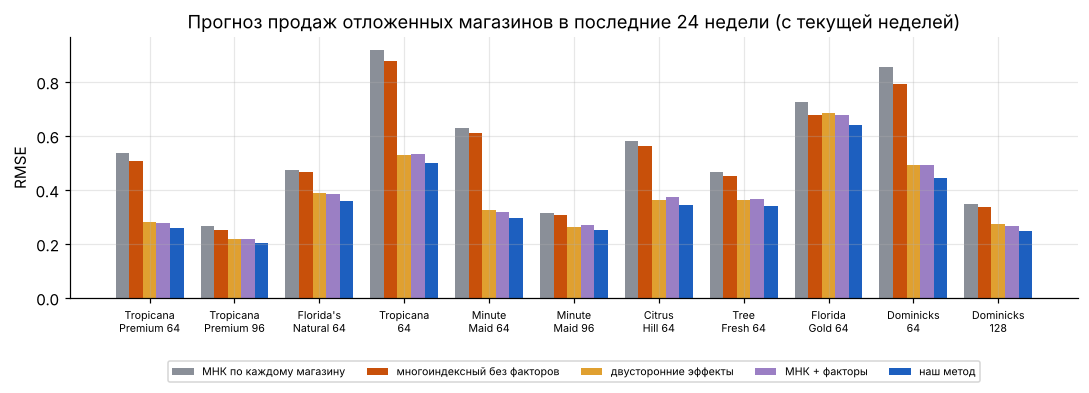

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.8))
xs = np.arange(11); w = 0.16
cols = ['#8a8f98', '#c8500a', '#e0a030', '#9b7fc4', '#1d5fbf']
for j, (k, c) in enumerate(zip(names, cols)):
    ax.bar(xs + (j - 2) * w, tab[k].values[:11], width=w, color=c, label=k)
ax.set_xticks(xs); ax.set_xticklabels([b.replace(' ', '\n', 1) for b in BRANDS], fontsize=7)
ax.set_ylabel('RMSE'); ax.set_title('Прогноз продаж отложенных магазинов в последние 24 недели (с текущей неделей)')
ax.legend(fontsize=7, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()


## Итоги

1. **Прогноз с текущей неделей.** Если продажи части магазинов в ту же неделю известны, наш метод даёт наименьшую ошибку **во всех 11 марках**. Средний RMSE 0.353 против 0.379–0.380 у МНК с факторами и двусторонних эффектов и 0.53–0.56 у методов без факторов. Выигрыш над лучшими конкурентами около 7%. Он получается за счёт малого ранга: наклоны оцениваются точнее, чем при отдельной регрессии в каждом магазине.
2. **Общий недельный шок есть.** В остатках один фактор явно доминирует. После его учёта средняя корреляция остатков между магазинами падает с 0.67 до 0.11 (марка Tropicana Premium 64).
3. **Эластичности.** Собственная эластичность по цене у всех магазинов отрицательная. С учётом факторов она по модулю меньше (для Tropicana Premium 64 медиана −1.8 против −3.1 без факторов), а разброс между магазинами у нашего метода наименьший.
4. **Прогноз без текущей недели.** Если продаж других магазинов в ту же неделю нет, лучше прогнозируют модели без факторов (средний RMSE 0.531 против 0.60–0.63). Это не противоречие. Сеть меняет цены одновременно с рекламой и другими общими мерами, и модели без факторов приписывают эффект этих мер цене. Для прогноза при сохранении такой практики это полезно. Но для вопроса «что будет, если изменить цену в одном магазине» нужна эластичность, очищенная от общих шоков, то есть оценка с факторами.
5. **Скорость.** С пропусками шаг по факторам сам итеративный (чередование нагрузок и факторов по наблюдённым клеткам), и алгоритм сходится медленнее, чем на полных данных: для Tropicana Premium 64 понадобилось 137 итераций. Ускорить можно точным решением шага по факторам или EM-подходом.
